# Business Performance & Operational Analytics Dashboard

**Name:** SOUMYA RANJAN BHOLA  
**Registered Email ID:** soumyaranjan0359@gmail.com  
**Project Title:** Business Performance & Operational Analytics Dashboard  
**Tools Used:** Python, Pandas, NumPy, Matplotlib, Seaborn

## Project objective
Analyze operational and sales performance, calculate key performance indicators (KPIs), compare regions and product categories, visualize trends, and turn findings into practical recommendations.

### Dataset note
The accompanying `business_operations_raw.csv` is **synthetic practice data created for this project**, not real company data. It includes a few deliberate data-quality issues (missing values, one invalid units value, a missing date, and a duplicate row) so the cleaning steps can be demonstrated.

### Tools
- Python
- pandas for data cleaning and analysis
- Matplotlib and Seaborn for charts

### How to run
1. Keep this notebook and `business_operations_raw.csv` in the same folder.
2. Open the notebook in Jupyter Notebook, JupyterLab, or Google Colab.
3. Run cells from top to bottom.

## 1. Import libraries
A library is a collection of ready-made tools. We use pandas for tables and Matplotlib/Seaborn for charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

DATA_FILE = Path("/content/business_operations_raw.csv")
df_raw = pd.read_csv(DATA_FILE, parse_dates=["OrderDate"])

print("Raw dataset shape:", df_raw.shape)
display(df_raw.head())

Raw dataset shape: (1501, 12)


,OrderID,OrderDate,Region,Department,ProductCategory,UnitsSold,Revenue,Cost,DeliveryDays,CustomerSatisfaction,Returned,RevenueTarget
0,ORD100774,2025-01-01,South,Online,Sports,7,9872.11,6851.26,9.6,3.9,0,9212.84
1,ORD101020,2025-01-01,North,Retail,Beauty,3,2659.43,1389.38,3.7,3.3,0,2546.56
2,ORD101389,2025-01-01,Central,Online,Sports,2,2835.59,1567.19,5.3,4.4,0,3146.29
3,ORD100429,2025-01-02,East,Retail,Sports,8,7407.84,4863.10,2.4,4.2,0,7694.56
4,ORD100421,2025-01-02,East,Online,Home & Kitchen,5,6289.93,4681.23,2.8,4.8,0,7017.42


## 2. Understand the dataset
`shape` tells us the number of rows and columns. `info()` shows data types and missing values. `describe()` summarizes numeric columns.

In [2]:
print("Rows and columns:", df_raw.shape)
df_raw.info()
display(df_raw.describe().round(2))
display(df_raw.isna().sum().rename("Missing values").to_frame())

Rows and columns: (1501, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1501 entries, 0 to 1500
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   OrderID               1501 non-null   object        
 1   OrderDate             1500 non-null   datetime64[ns]
 2   Region                1499 non-null   object        
 3   Department            1501 non-null   object        
 4   ProductCategory       1501 non-null   object        
 5   UnitsSold             1501 non-null   int64         
 6   Revenue               1500 non-null   float64       
 7   Cost                  1501 non-null   float64       
 8   DeliveryDays          1501 non-null   float64       
 9   CustomerSatisfaction  1498 non-null   float64       
 10  Returned              1501 non-null   int64         
 11  RevenueTarget         1501 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int64(2), obj

,OrderDate,UnitsSold,Revenue,Cost,DeliveryDays,CustomerSatisfaction,Returned,RevenueTarget
count,1500,1501.00,1500.00,1501.00,1501.00,1498.00,1501.00,1501.00
mean,2025-11-08 17:05:16.800000256,5.97,11788.64,7707.23,3.80,4.13,0.07,12020.14
min,2025-01-01 00:00:00,-2.00,453.06,276.79,0.50,2.30,0.00,460.78
25%,2025-06-21 00:00:00,3.00,4155.38,2713.45,2.60,3.70,0.00,4196.26
50%,2025-11-17 12:00:00,6.00,7862.04,5139.65,3.80,4.20,0.00,7993.20
75%,2026-04-06 06:00:00,9.00,14872.00,9593.32,4.90,4.50,0.00,15215.86
max,2026-08-31 00:00:00,11.00,67082.85,47275.94,9.60,5.00,1.00,67005.83
std,NaN,3.14,11553.14,7694.33,1.68,0.54,0.25,11858.37


,Missing values
OrderID,0
OrderDate,1
Region,2
Department,0
ProductCategory,0
UnitsSold,0
Revenue,1
Cost,0
DeliveryDays,0
CustomerSatisfaction,3


## 3. Data cleaning and quality checks
We make a working copy so the original imported data remains unchanged.

Cleaning decisions:
- Remove exact duplicate rows.
- Convert `OrderDate` to a date type.
- Remove rows with missing order date or missing revenue because they cannot support time/revenue analysis.
- Replace missing region with `Unknown`.
- Replace missing satisfaction with the median satisfaction score.
- Treat negative `UnitsSold` as invalid and remove that row.
- Check that cost and revenue are non-negative.

In [3]:
df = df_raw.copy()

# Remove exact duplicate rows
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates()

# Ensure date column has datetime type
df["OrderDate"] = pd.to_datetime(df["OrderDate"], errors="coerce")

# Remove rows missing essential fields
before_essential = len(df)
df = df.dropna(subset=["OrderDate", "Revenue"])
removed_essential = before_essential - len(df)

# Handle missing categorical and satisfaction values
df["Region"] = df["Region"].fillna("Unknown")
df["CustomerSatisfaction"] = df["CustomerSatisfaction"].fillna(
    df["CustomerSatisfaction"].median()
)

# Remove invalid quantities and impossible negative financial values
invalid_units = int((df["UnitsSold"] <= 0).sum())
df = df[df["UnitsSold"] > 0].copy()
df = df[(df["Revenue"] >= 0) & (df["Cost"] >= 0)].copy()

# Add analysis columns
df["Profit"] = df["Revenue"] - df["Cost"]
df["ProfitMarginPct"] = np.where(df["Revenue"] > 0, df["Profit"] / df["Revenue"] * 100, np.nan)
df["OrderMonth"] = df["OrderDate"].dt.to_period("M").astype(str)

print(f"Exact duplicate rows found: {duplicate_count}")
print(f"Rows removed for missing date/revenue: {removed_essential}")
print(f"Rows removed for invalid UnitsSold: {invalid_units}")
print("Cleaned dataset shape:", df.shape)
display(df.head())

Exact duplicate rows found: 1
Rows removed for missing date/revenue: 2
Rows removed for invalid UnitsSold: 1
Cleaned dataset shape: (1497, 15)


,OrderID,OrderDate,Region,Department,ProductCategory,UnitsSold,Revenue,Cost,DeliveryDays,CustomerSatisfaction,Returned,RevenueTarget,Profit,ProfitMarginPct,OrderMonth
0,ORD100774,2025-01-01,South,Online,Sports,7,9872.11,6851.26,9.6,3.9,0,9212.84,3020.85,30.599841,2025-01
1,ORD101020,2025-01-01,North,Retail,Beauty,3,2659.43,1389.38,3.7,3.3,0,2546.56,1270.05,47.756474,2025-01
2,ORD101389,2025-01-01,Central,Online,Sports,2,2835.59,1567.19,5.3,4.4,0,3146.29,1268.40,44.731432,2025-01
3,ORD100429,2025-01-02,East,Retail,Sports,8,7407.84,4863.10,2.4,4.2,0,7694.56,2544.74,34.351984,2025-01
4,ORD100421,2025-01-02,East,Online,Home & Kitchen,5,6289.93,4681.23,2.8,4.8,0,7017.42,1608.70,25.575801,2025-01


### Check the cleaning result
Ideally, the key fields used in the analysis should now be complete, and there should be no duplicate rows. Some columns such as `Region` may contain the label `Unknown` where the source value was missing.

In [4]:
quality_report = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Data type": df.dtypes.astype(str),
    "Unique values": df.nunique()
})
display(quality_report)
print("Remaining duplicate rows:", int(df.duplicated().sum()))
print("Minimum units sold:", df["UnitsSold"].min())
print("Minimum revenue:", df["Revenue"].min())

,Missing values,Data type,Unique values
OrderID,0,object,1497
OrderDate,0,datetime64[ns],555
Region,0,object,6
Department,0,object,3
ProductCategory,0,object,5
UnitsSold,0,int64,11
Revenue,0,float64,1497
Cost,0,float64,1496
DeliveryDays,0,float64,84
CustomerSatisfaction,0,float64,26


Remaining duplicate rows: 0
Minimum units sold: 1
Minimum revenue: 453.06


## 4. Exploratory Data Analysis (EDA)
EDA means exploring a dataset to understand its size, distributions, patterns, and unusual values before drawing conclusions.

In [5]:
print("Analysis period:", df["OrderDate"].min().date(), "to", df["OrderDate"].max().date())
print("Orders analyzed:", df["OrderID"].nunique())
print("Regions:", df["Region"].nunique())
print("Product categories:", df["ProductCategory"].nunique())

display(df[["UnitsSold", "Revenue", "Cost", "Profit", "DeliveryDays", "CustomerSatisfaction"]].describe().round(2))

Analysis period: 2025-01-01 to 2026-08-31
Orders analyzed: 1497
Regions: 6
Product categories: 5


,UnitsSold,Revenue,Cost,Profit,DeliveryDays,CustomerSatisfaction
count,1497.00,1497.00,1497.00,1497.00,1497.00,1497.00
mean,5.98,11792.21,7714.62,4077.59,3.81,4.13
std,3.14,11561.35,7700.83,4317.45,1.68,0.54
min,1.00,453.06,276.79,85.79,0.50,2.30
25%,3.00,4156.96,2715.97,1311.56,2.60,3.70
50%,6.00,7856.71,5139.65,2624.29,3.80,4.20
75%,9.00,14874.41,9593.32,5100.84,4.90,4.50
max,11.00,67082.85,47275.94,29498.78,9.60,5.00


## 5. Calculate key performance indicators (KPIs)
These KPIs describe the dataset. Here, each row represents an order record, so total revenue is the sum of the `Revenue` column and order count uses unique `OrderID` values.

- **Total Revenue:** total recorded sales value.
- **Total Cost:** total recorded cost.
- **Total Profit:** revenue minus cost.
- **Profit Margin:** profit divided by revenue, multiplied by 100.
- **Average Order Value (AOV):** revenue divided by unique orders.
- **Return Rate:** percentage of records marked as returned.
- **Average Delivery Time:** average delivery days.
- **Average Satisfaction:** mean customer satisfaction score.

In [6]:
total_revenue = df["Revenue"].sum()
total_cost = df["Cost"].sum()
total_profit = df["Profit"].sum()
profit_margin = total_profit / total_revenue * 100 if total_revenue else np.nan
order_count = df["OrderID"].nunique()
aov = total_revenue / order_count if order_count else np.nan
return_rate = df["Returned"].mean() * 100
avg_delivery = df["DeliveryDays"].mean()
avg_satisfaction = df["CustomerSatisfaction"].mean()

kpis = pd.DataFrame({
    "KPI": ["Total Revenue", "Total Cost", "Total Profit", "Profit Margin (%)",
            "Unique Orders", "Average Order Value", "Return Rate (%)",
            "Average Delivery Days", "Average Customer Satisfaction"],
    "Value": [total_revenue, total_cost, total_profit, profit_margin,
              order_count, aov, return_rate, avg_delivery, avg_satisfaction]
})
display(kpis.style.format({"Value": "{:,.2f}"}))

,KPI,Value
0,Total Revenue,"17,652,945.51"
1,Total Cost,"11,548,792.11"
2,Total Profit,"6,104,153.40"
3,Profit Margin (%),34.58
4,Unique Orders,"1,497.00"
5,Average Order Value,"11,792.21"
6,Return Rate (%),6.55
7,Average Delivery Days,3.81
8,Average Customer Satisfaction,4.13


## 6. Monthly revenue and profit trends
Monthly aggregation helps show whether performance is rising, falling, or fluctuating. The last month in the dataset may be incomplete, so interpret it carefully.

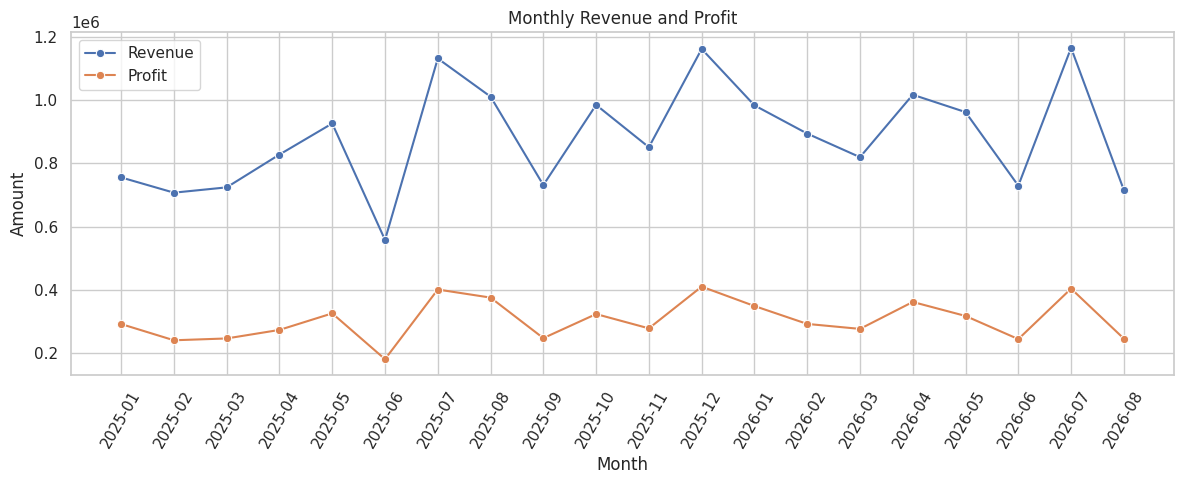

,OrderMonth,Revenue,Profit,Orders
8,2025-09,731463.96,248393.13,58
9,2025-10,984429.34,324378.16,81
10,2025-11,850938.26,279235.16,74
11,2025-12,1161010.27,410925.90,111
12,2026-01,983050.92,349761.43,77
13,2026-02,893962.16,293254.67,65
14,2026-03,819500.94,277571.01,73
15,2026-04,1016568.36,362572.90,86
16,2026-05,961745.84,318374.40,80
17,2026-06,729466.66,245325.73,66


In [7]:
monthly = df.groupby("OrderMonth", as_index=False).agg(
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum"),
    Orders=("OrderID", "nunique")
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly, x="OrderMonth", y="Revenue", marker="o", label="Revenue")
sns.lineplot(data=monthly, x="OrderMonth", y="Profit", marker="o", label="Profit")
plt.title("Monthly Revenue and Profit")
plt.xlabel("Month")
plt.ylabel("Amount")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

display(monthly.tail(12).round(2))

## 7. Compare product categories
This comparison identifies categories contributing the most revenue and profit. High revenue does not automatically mean the highest profit margin.

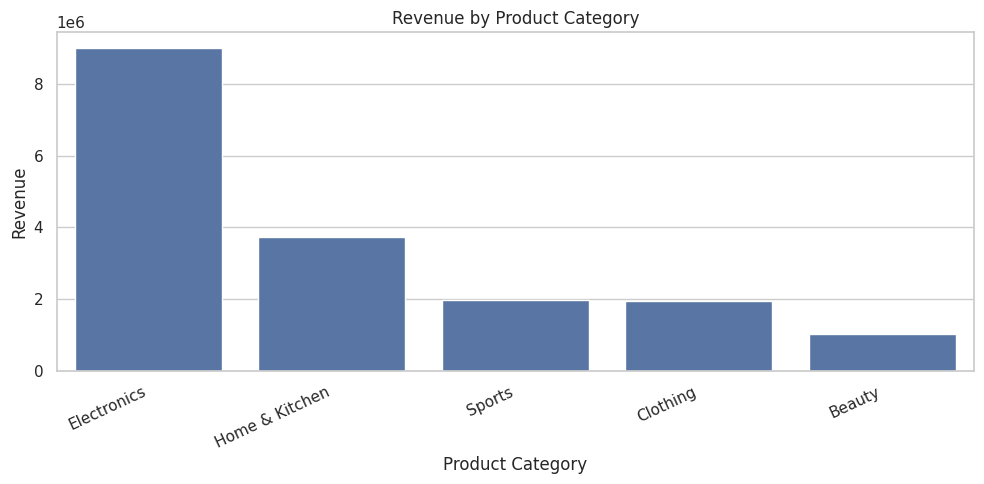

,ProductCategory,Revenue,Profit,Units,Orders,ProfitMarginPct,ReturnRatePct
2,Electronics,8982933.12,3098357.68,2073,342,34.49,5.26
3,Home & Kitchen,3730825.00,1288674.30,1990,324,34.54,5.86
4,Sports,1967162.04,684178.41,1419,251,34.78,7.17
1,Clothing,1949314.61,683705.13,2033,337,35.07,8.61
0,Beauty,1022710.74,349237.88,1441,243,34.15,5.76


In [8]:
category_summary = df.groupby("ProductCategory", as_index=False).agg(
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum"),
    Units=("UnitsSold", "sum"),
    Orders=("OrderID", "nunique"),
    ReturnRate=("Returned", "mean")
)
category_summary["ProfitMarginPct"] = category_summary["Profit"] / category_summary["Revenue"] * 100
category_summary["ReturnRatePct"] = category_summary["ReturnRate"] * 100
category_summary = category_summary.sort_values("Revenue", ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=category_summary, x="ProductCategory", y="Revenue")
plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

display(category_summary.drop(columns="ReturnRate").round(2))

## 8. Compare regions
Regional analysis helps compare revenue, profit, delivery time, and satisfaction across operating areas.

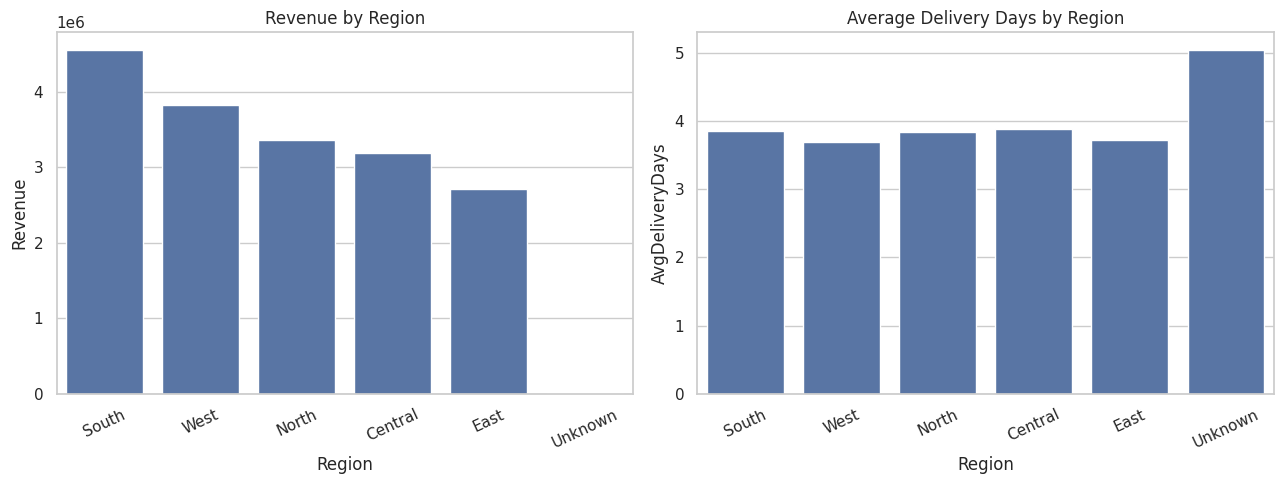

,Region,Revenue,Profit,AvgDeliveryDays,AvgSatisfaction,Orders,ProfitMarginPct
3,South,4558331.02,1655909.35,3.86,4.09,349,36.33
5,West,3819055.47,1507227.70,3.70,4.13,312,39.47
2,North,3364531.46,1192260.46,3.84,4.14,299,35.44
0,Central,3191491.32,939530.55,3.89,4.17,282,29.44
1,East,2706052.02,805644.66,3.73,4.12,253,29.77
4,Unknown,13484.22,3580.68,5.05,4.50,2,26.55


In [9]:
region_summary = df.groupby("Region", as_index=False).agg(
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum"),
    AvgDeliveryDays=("DeliveryDays", "mean"),
    AvgSatisfaction=("CustomerSatisfaction", "mean"),
    Orders=("OrderID", "nunique")
)
region_summary["ProfitMarginPct"] = region_summary["Profit"] / region_summary["Revenue"] * 100
region_summary = region_summary.sort_values("Revenue", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=region_summary, x="Region", y="Revenue", ax=axes[0])
axes[0].set_title("Revenue by Region")
sns.barplot(data=region_summary, x="Region", y="AvgDeliveryDays", ax=axes[1])
axes[1].set_title("Average Delivery Days by Region")
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

display(region_summary.round(2))

## 9. Operational relationships
A scatter plot can help us inspect whether longer delivery times are associated with lower customer satisfaction. This is an association check, not proof that delivery time causes satisfaction to change.

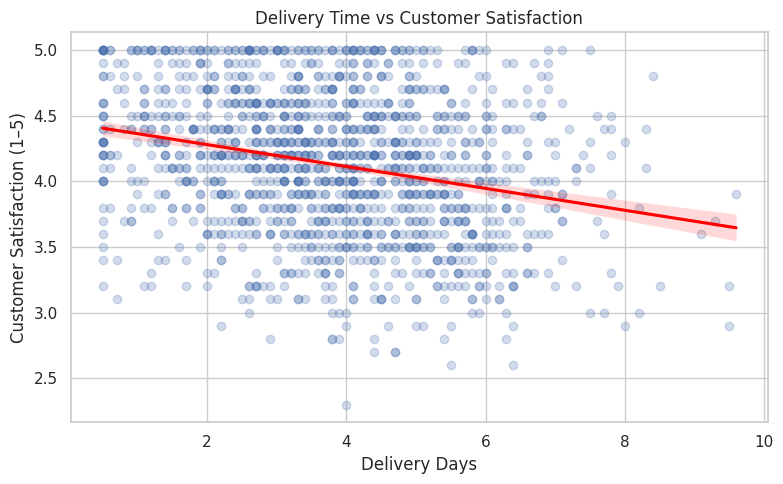

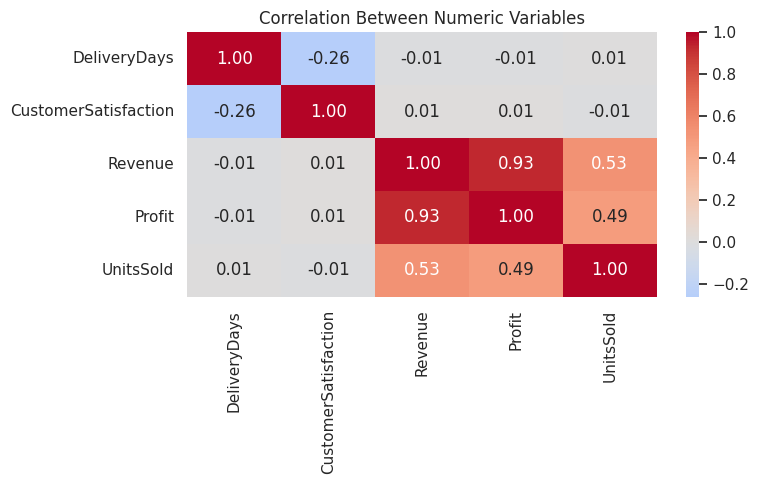

,DeliveryDays,CustomerSatisfaction,Revenue,Profit,UnitsSold
DeliveryDays,1.00,-0.26,-0.01,-0.01,0.01
CustomerSatisfaction,-0.26,1.00,0.01,0.01,-0.01
Revenue,-0.01,0.01,1.00,0.93,0.53
Profit,-0.01,0.01,0.93,1.00,0.49
UnitsSold,0.01,-0.01,0.53,0.49,1.00


In [10]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="DeliveryDays", y="CustomerSatisfaction",
            scatter_kws={"alpha": 0.25}, line_kws={"color": "red"})
plt.title("Delivery Time vs Customer Satisfaction")
plt.xlabel("Delivery Days")
plt.ylabel("Customer Satisfaction (1–5)")
plt.tight_layout()
plt.show()

correlation = df[["DeliveryDays", "CustomerSatisfaction", "Revenue", "Profit", "UnitsSold"]].corr(numeric_only=True)
plt.figure(figsize=(8, 5))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Numeric Variables")
plt.tight_layout()
plt.show()
display(correlation.round(2))

## 10. Department performance
Compare online, retail, and wholesale performance to see how revenue and profit are distributed.

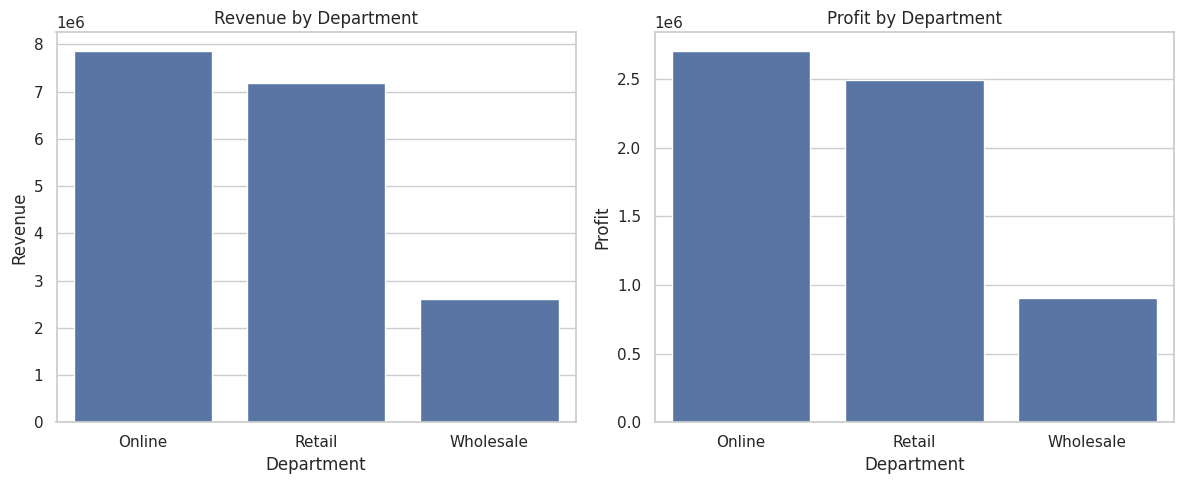

,Department,Revenue,Profit,Orders,ProfitMarginPct
0,Online,7859569.18,2703210.06,675,34.39
1,Retail,7179525.56,2493253.21,601,34.73
2,Wholesale,2613850.77,907690.13,221,34.73


In [11]:
department_summary = df.groupby("Department", as_index=False).agg(
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum"),
    Orders=("OrderID", "nunique")
)
department_summary["ProfitMarginPct"] = department_summary["Profit"] / department_summary["Revenue"] * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(data=department_summary, x="Department", y="Revenue", ax=axes[0])
axes[0].set_title("Revenue by Department")
sns.barplot(data=department_summary, x="Department", y="Profit", ax=axes[1])
axes[1].set_title("Profit by Department")
plt.tight_layout()
plt.show()
display(department_summary.round(2))

## 11. Generate data-based observations
The cells below identify the highest-revenue category and region, and the region with the longest average delivery time. These are descriptive observations from this dataset, not universal business facts. Review the summary tables and plots before writing your final report.

In [12]:
top_category = category_summary.iloc[0]
top_region = region_summary.sort_values("Revenue", ascending=False).iloc[0]
slowest_region = region_summary.sort_values("AvgDeliveryDays", ascending=False).iloc[0]
lowest_margin_category = category_summary.sort_values("ProfitMarginPct").iloc[0]

print(f"Highest revenue category: {top_category['ProductCategory']} "
      f"(revenue {top_category['Revenue']:,.2f}).")
print(f"Highest revenue region: {top_region['Region']} "
      f"(revenue {top_region['Revenue']:,.2f}).")
print(f"Longest average delivery time: {slowest_region['Region']} "
      f"({slowest_region['AvgDeliveryDays']:.2f} days).")
print(f"Lowest-margin category: {lowest_margin_category['ProductCategory']} "
      f"({lowest_margin_category['ProfitMarginPct']:.2f}% margin).")

Highest revenue category: Electronics (revenue 8,982,933.12).
Highest revenue region: South (revenue 4,558,331.02).
Longest average delivery time: Unknown (5.05 days).
Lowest-margin category: Beauty (34.15% margin).


## 12. Recommendations framework
Use the actual output from your notebook to complete these recommendations. Avoid claiming a cause unless the data supports it.

1. **Revenue:** Investigate the leading category and region; check whether performance is consistent across months.
2. **Profitability:** Review costs and pricing for categories with lower profit margins.
3. **Operations:** Investigate regions with longer delivery times and compare them with customer satisfaction.
4. **Returns:** Review return rates by category to find areas where product descriptions, sizing, packaging, or quality checks may need investigation.
5. **Monitoring:** Refresh the analysis monthly and compare KPIs against explicit business targets.

### Limitations
- The data is synthetic and does not represent an actual company.
- The dataset does not include marketing spend, inventory, staffing, or detailed customer identifiers.
- Relationships between variables are not proof of causation.
- Any conclusion should be checked against real business data before being used for decisions.

## 13. Export cleaned data and summary tables
This creates reusable CSV files in the current notebook folder. Keep the raw dataset as well so the cleaning process is reproducible.

In [13]:
df.to_csv("business_operations_cleaned.csv", index=False)
monthly.to_csv("monthly_performance_summary.csv", index=False)
category_summary.to_csv("category_performance_summary.csv", index=False)
region_summary.to_csv("regional_performance_summary.csv", index=False)
department_summary.to_csv("department_performance_summary.csv", index=False)
kpis.to_csv("business_kpis.csv", index=False)

print("Export complete. Files saved:")
for filename in [
    "business_operations_cleaned.csv",
    "monthly_performance_summary.csv",
    "category_performance_summary.csv",
    "regional_performance_summary.csv",
    "department_performance_summary.csv",
    "business_kpis.csv"
]:
    print("-", filename)

Export complete. Files saved:
- business_operations_cleaned.csv
- monthly_performance_summary.csv
- category_performance_summary.csv
- regional_performance_summary.csv
- department_performance_summary.csv
- business_kpis.csv


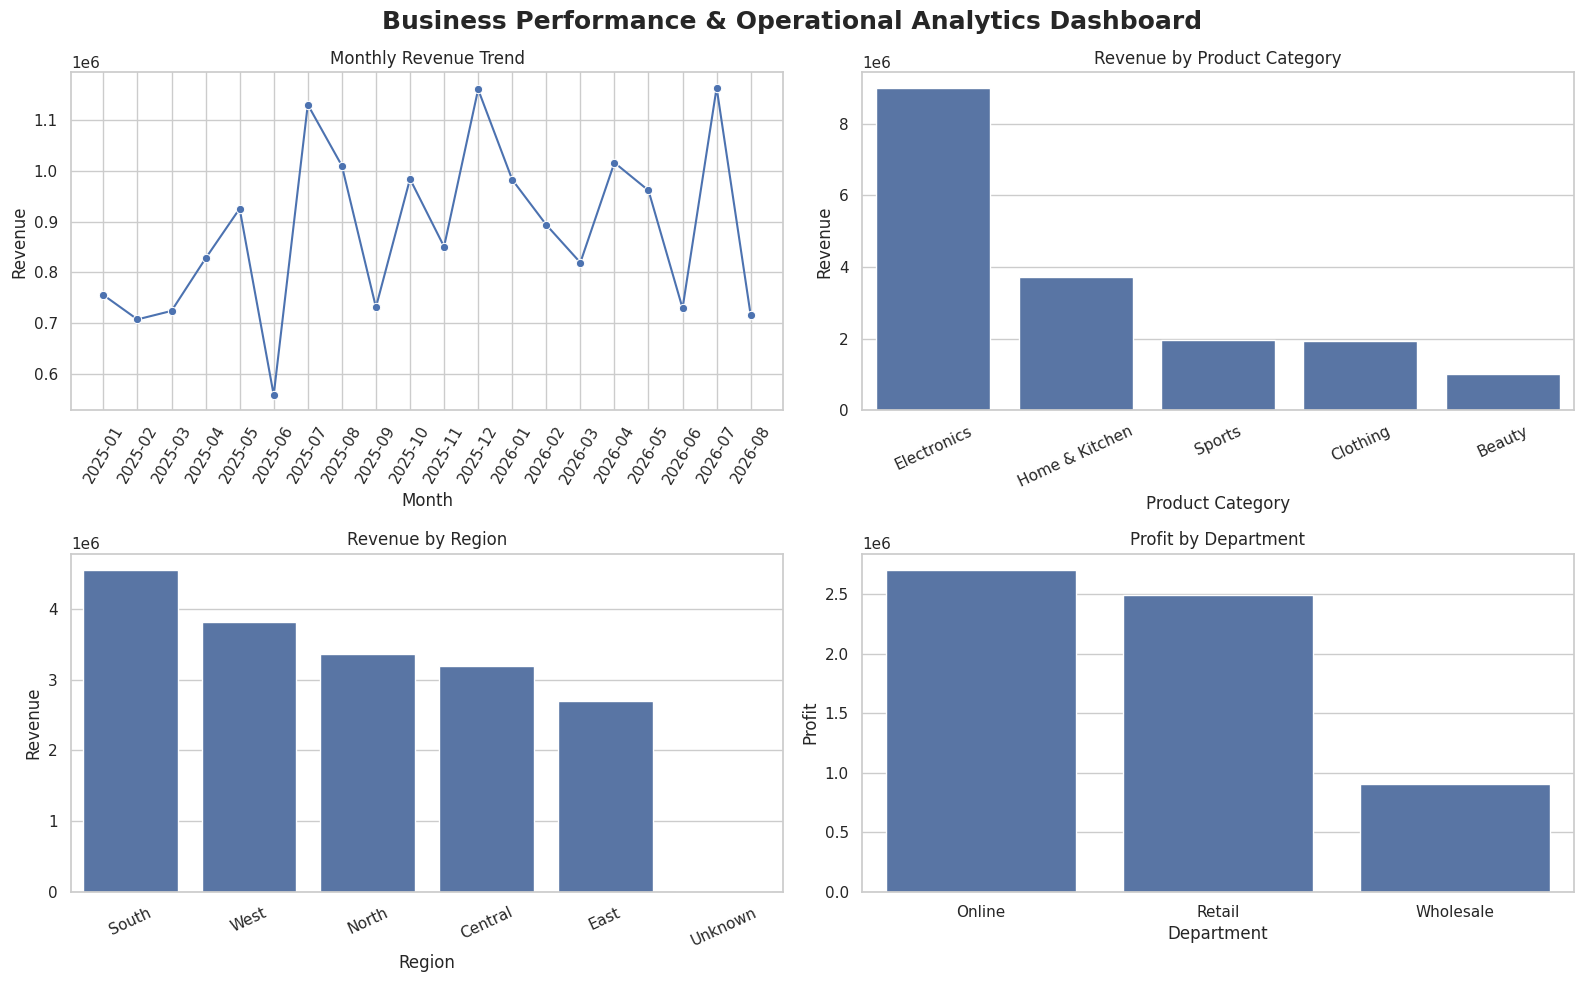

                 BUSINESS KPI SUMMARY
Total Revenue              : 17,652,945.51
Total Profit               : 6,104,153.40
Profit Margin              : 34.58%
Average Order Value        : 11,792.21
Return Rate                : 6.55%
Average Delivery Days      : 3.81
Customer Satisfaction      : 4.13/5


In [14]:
# FINAL BUSINESS PERFORMANCE DASHBOARD

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Monthly Revenue Trend
sns.lineplot(
    data=monthly,
    x="OrderMonth",
    y="Revenue",
    marker="o",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Monthly Revenue Trend")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Revenue")
axes[0, 0].tick_params(axis="x", rotation=60)

# 2. Revenue by Product Category
sns.barplot(
    data=category_summary,
    x="ProductCategory",
    y="Revenue",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Revenue by Product Category")
axes[0, 1].set_xlabel("Product Category")
axes[0, 1].set_ylabel("Revenue")
axes[0, 1].tick_params(axis="x", rotation=25)

# 3. Revenue by Region
sns.barplot(
    data=region_summary,
    x="Region",
    y="Revenue",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Revenue by Region")
axes[1, 0].set_xlabel("Region")
axes[1, 0].set_ylabel("Revenue")
axes[1, 0].tick_params(axis="x", rotation=25)

# 4. Profit by Department
sns.barplot(
    data=department_summary,
    x="Department",
    y="Profit",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Profit by Department")
axes[1, 1].set_xlabel("Department")
axes[1, 1].set_ylabel("Profit")

fig.suptitle(
    "Business Performance & Operational Analytics Dashboard",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# KPI Summary
print("=" * 60)
print("                 BUSINESS KPI SUMMARY")
print("=" * 60)
print(f"Total Revenue              : {total_revenue:,.2f}")
print(f"Total Profit               : {total_profit:,.2f}")
print(f"Profit Margin              : {profit_margin:.2f}%")
print(f"Average Order Value        : {aov:,.2f}")
print(f"Return Rate                : {return_rate:.2f}%")
print(f"Average Delivery Days      : {avg_delivery:.2f}")
print(f"Customer Satisfaction      : {avg_satisfaction:.2f}/5")
print("=" * 60)

## 14. Final submission checklist
- [ ] Run every cell from top to bottom without errors.
- [ ] Review the charts and KPI values generated on your machine.
- [ ] Include the raw CSV dataset and any exported summaries you want to submit.